**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



**Set global variable**

In [2]:
## init: region folder
vec = c("fcc_astarr_macs_input_overlap", "fcc_astarr_macs_input_union")
names(vec) = vec

VEC_TXT_FOLDER = vec
for (txt in vec) {cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


In [3]:
vec = c("CRISPR", "CRISPRi-HCRFF", "CRISPRi-Growth", "ENCODE-rE2G Benchmark")
names(vec) = vec
VEC_TXT_ASSAY_OUT = vec

vec = c("ASTARR", "WSTARR", "LMPRA", "TMPRA", "ATAC")
names(vec) = vec
VEC_TXT_ASSAY_INP = vec

**Check input files**

In [4]:
txt_folder = "fcc_astarr_macs_input_union"
txt_fdiry  = file.path(FD_RES, "analysis_fcc_correlation", txt_folder)
txt_fname  = "result.cripsr_vs_starrmpra.logit.stats.pool.*.tsv"
txt_fglob  = file.path(txt_fdiry, txt_fname)

vec = Sys.glob(txt_fglob)
for (txt in vec) {cat(txt, "\n")}

/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/analysis_fcc_correlation/fcc_astarr_macs_input_union/result.cripsr_vs_starrmpra.logit.stats.pool.distal.tsv 
/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/analysis_fcc_correlation/fcc_astarr_macs_input_union/result.cripsr_vs_starrmpra.logit.stats.pool.proximal.tsv 


## Import data

In [5]:
### set directory
txt_foldr = "fcc_astarr_macs_input_union"
txt_fdiry = file.path(FD_RES, "analysis_fcc_correlation", txt_foldr)
txt_fname = "result.cripsr_vs_starrmpra.logit.stats.pool.proximal.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

### read table
dat = read_tsv(txt_fpath, show_col_types = FALSE)

### assign and show
dat_logit_stats_pool_proximal = dat
print(dim(dat))
fun_display_table(head(dat, 3))

[1] 140  12


CutOff_CRISPR,Assay_CRISPR,Assay_STARRMPRA,OR,OR_CI_Lower,OR_CI_Upper,Log10OR,Log10OR_CI_Lower,Log10OR_CI_Upper,Pvalue,Total,Count
0.01,CRISPRi-HCRFF,ATAC,1.669983,0.9914345,2.812938,0.2227121,-0.0037360,0.4491602,0.0539014,705,169
0.01,CRISPRi-HCRFF,STARRMPRA,1.039863,0.6566306,1.646763,0.0169762,-0.1826788,0.2166312,0.8676448,705,536
0.01,CRISPRi-Growth,ATAC,1.640094,1.5532066,1.731841,0.2148686,0.1912292,0.2385081,0.0000000,61978,17185


In [6]:
### set directory
txt_foldr = "fcc_astarr_macs_input_union"
txt_fdiry = file.path(FD_RES, "analysis_fcc_correlation", txt_foldr)
txt_fname = "result.cripsr_vs_starrmpra.logit.stats.pool.distal.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

### read table
dat = read_tsv(txt_fpath, show_col_types = FALSE)

### assign and show
dat_logit_stats_pool_distal = dat
print(dim(dat))
fun_display_table(head(dat, 3))

[1] 140  12


CutOff_CRISPR,Assay_CRISPR,Assay_STARRMPRA,OR,OR_CI_Lower,OR_CI_Upper,Log10OR,Log10OR_CI_Lower,Log10OR_CI_Upper,Pvalue,Total,Count
0.01,CRISPRi-HCRFF,ATAC,3.441338,2.1316597,5.555674,0.5367273,0.3287179,0.7447368,0.0000004,4614,1161
0.01,CRISPRi-HCRFF,STARRMPRA,2.035535,1.6534844,2.505862,0.3086786,0.2184001,0.3989571,0.0000000,4614,3453
0.01,CRISPRi-Growth,ATAC,1.125918,0.9607965,1.319416,0.0515066,-0.0173686,0.1203819,0.1427271,232791,63103


## Plot odds ratio for proximal regions

**Set plot text style**

In [7]:
THEME_TEXT = theme(
    title        = element_text(size = 16),
    axis.text.x  = element_text(size = 16),
    axis.text.y  = element_text(size = 16),
    axis.title.x = element_text(size = 16),
    axis.title.y = element_text(size = 16),
    legend.text  = element_text(size = 14),
    legend.title = element_text(size = 14) 
)

**Test and check get threshold for proximal regions**

In [8]:
c(0.01, 0.03, 0.05, 0.07, seq(0.1, 0.5, 0.1))

[1] 0.01 0.03 0.05 0.07 0.10 0.20 0.30 0.40 0.50

In [9]:
dat = dat_logit_stats_pool_proximal
unique(dat$CutOff_CRISPR)

[1] 0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.10 0.20 0.30 0.40 0.50

In [10]:
dat = dat_logit_stats_pool_proximal
dat = dat %>% dplyr::mutate(CutOff_Label = as.character(CutOff_CRISPR))
vec = c(0.01, 0.03, 0.05, 0.07, seq(0.1, 0.5, 0.1))
vec = as.character(vec)
dat = dat %>% dplyr::filter(CutOff_Label %in% vec, Assay_CRISPR == "CRISPR_Pool")
unique(dat$CutOff_CRISPR)

[1] 0.01 0.03 0.05 0.07 0.10 0.20 0.30 0.40 0.50

**Generate plots**

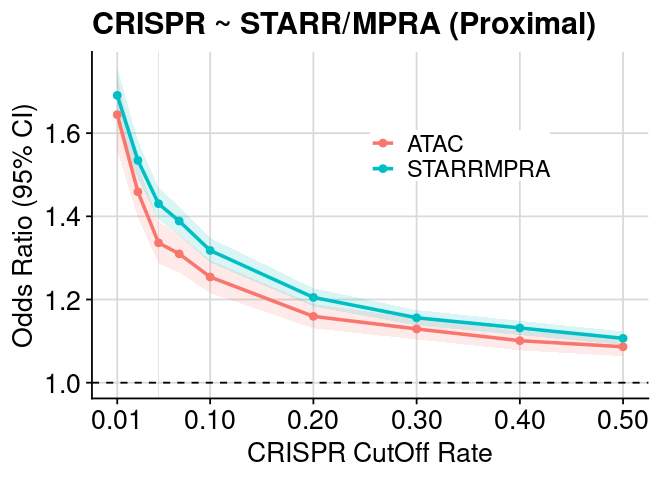

In [11]:
### init
dat = dat_logit_stats_pool_proximal

### get threshold for proximal regions
dat = dat %>% dplyr::mutate(CutOff_Label = as.character(CutOff_CRISPR))
vec = c(0.01, 0.03, 0.05, 0.07, seq(0.1, 0.5, 0.1))
vec = as.character(vec)
dat = dat %>% dplyr::filter(CutOff_Label %in% vec, Assay_CRISPR == "CRISPR_Pool")

### set grid lines and labels
vec_num_break_total = c(0.01, 0.05, seq(0.1, 0.5, 0.1))
vec_num_break_major = c(0.01,       seq(0.1, 0.5, 0.1))
vec_num_break_minor = setdiff(vec_num_break_total, vec_num_break_major)

### generate plot
gpt = ggplot(dat, aes(x = CutOff_CRISPR, y = OR, group = Assay_STARRMPRA, color = Assay_STARRMPRA)) +
    geom_ribbon(
        aes(ymin = OR_CI_Lower, ymax = OR_CI_Upper, fill = Assay_STARRMPRA), 
        alpha = 0.15, 
        color = NA
    ) +
    geom_line(linewidth = 1) +
    geom_point(size = 1.8) +
    geom_hline(yintercept = 1, linetype = "dashed") +
    scale_x_continuous(
        breaks = vec_num_break_major,
        labels = scales::label_number(accuracy = 0.01),
        minor_breaks = vec_num_break_minor
    ) +
    scale_y_continuous(breaks = scales::pretty_breaks()) +
    theme_cowplot() +
    background_grid(major = "xy", minor = "x") +
    labs(x="CRISPR CutOff Rate", y = "Odds Ratio (95% CI)", title = "CRISPR ~ STARR/MPRA (Proximal)") +
    guides(fill = "none", color = guide_legend(title = NULL)) +
    theme(
        legend.background = element_rect(fill="white"),
        legend.position   = "inside",
        legend.position.inside = c(0.5, 0.7)
    ) +
    THEME_TEXT

### assign and show
gpt_export_logit_pool_proximal = gpt
options(repr.plot.height=4, repr.plot.width=5.5)
print(gpt)

## Plot odds ratio for distal regions

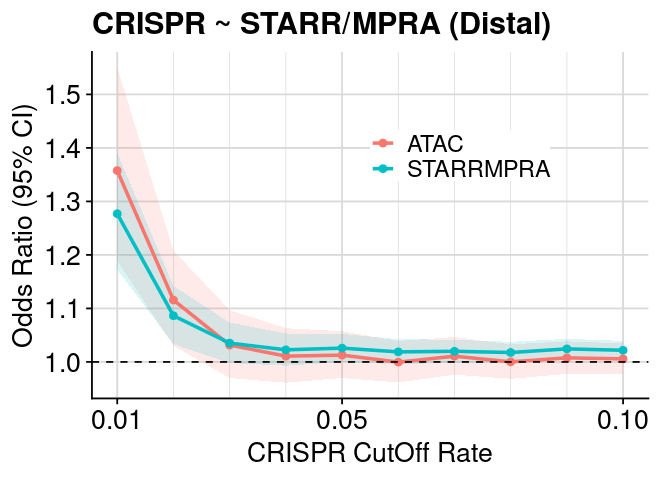

In [12]:
### init
dat = dat_logit_stats_pool_distal

### get threshold for proximal regions
dat = dat %>% dplyr::filter(CutOff_CRISPR <= 0.1, Assay_CRISPR == "CRISPR_Pool")

### set grid lines and labels
vec_num_break_total = seq(0, 0.1, 0.01)
vec_num_break_major = c(0.01, 0.05, 0.10)
vec_num_break_minor = setdiff(vec_num_break_total, vec_num_break_major)

### generate plot
gpt = ggplot(dat, aes(x = CutOff_CRISPR, y = OR, group = Assay_STARRMPRA, color = Assay_STARRMPRA)) +
    geom_ribbon(
        aes(ymin = OR_CI_Lower, ymax = OR_CI_Upper, fill = Assay_STARRMPRA), 
        alpha = 0.15, 
        color = NA
    ) +
    geom_line(linewidth = 1) +
    geom_point(size = 1.8) +
    geom_hline(yintercept = 1, linetype = "dashed") +
    scale_x_continuous(
        breaks = vec_num_break_major,
        labels = scales::label_number(accuracy = 0.01),
        minor_breaks = vec_num_break_minor
    ) +
    scale_y_continuous(breaks = scales::pretty_breaks()) +
    theme_cowplot() +
    background_grid(major = "xy", minor = "x") +
    labs(x="CRISPR CutOff Rate", y = "Odds Ratio (95% CI)", title = "CRISPR ~ STARR/MPRA (Distal)") +
    guides(fill = "none", color = guide_legend(title = NULL)) +
    theme(
        legend.background = element_rect(fill="white"),
        legend.position   = "inside",
        legend.position.inside = c(0.5, 0.7)
    ) +
    THEME_TEXT

### assign and show
gpt_export_logit_pool_distal = gpt
options(repr.plot.height=4, repr.plot.width=5.5)
print(gpt)

## Combine plots

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


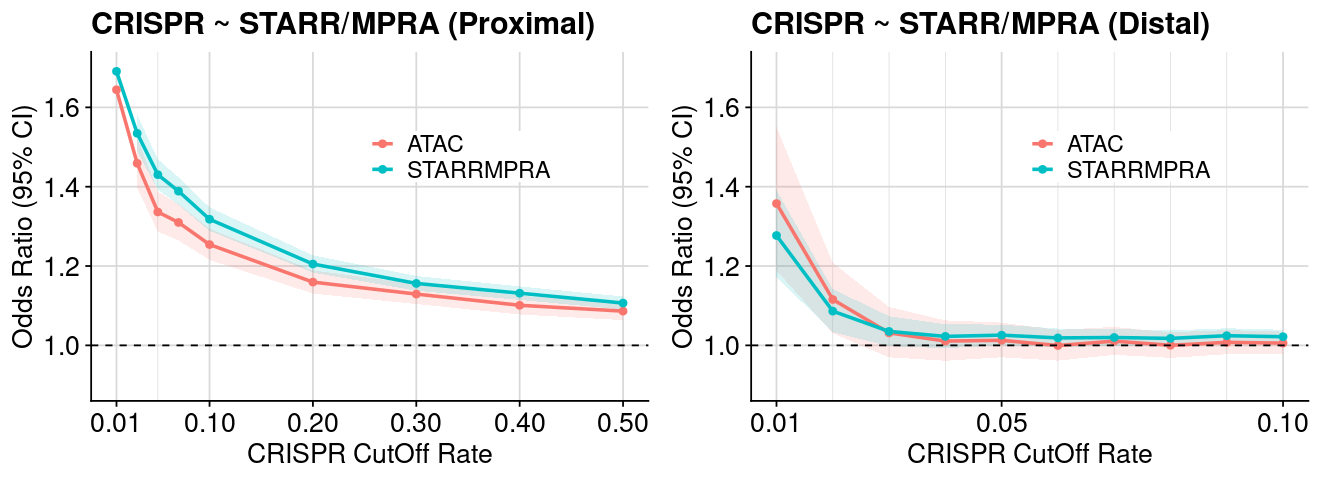

In [13]:
lst = list(gpt_export_logit_pool_proximal, gpt_export_logit_pool_distal)
lst = lapply(lst, function(gpt){
    gpt = gpt + scale_y_continuous(breaks = scales::pretty_breaks(), limits = c(0.9, 1.7))
})

plt = plot_grid(plotlist = lst, nrow = 1)

### assign and show
plt_export_logit_pool = plt
options(repr.plot.height=4, repr.plot.width=11)
print(plt)

## Export plots

In [14]:
plt_export = plt_export_logit_pool
txt_export = "fig.region_coverage_fcc.logit.odds_ratio.pool.proximal_distal"
num_height = 4
num_width  = 11

txt_fdiry = "./"
txt_fname = paste(txt_export, "png", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")

txt_fdiry = "./"
txt_fname = paste(txt_export, "svg", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")